<h1> Myonuclei analysis </h1>

---

In [1]:
import scanpy as sc
import numpy as np
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
all_data = ad.read_h5ad("processed_annotated.h5ad")

In [ ]:
print(all_data.obs.columns)

In [ ]:
sc.pl.umap(all_data, color=["cell_type", "sample_id"], legend_loc="on data")

In [ ]:
# subset myonuclei
myonuclei = all_data[all_data.obs["cell_type"].isin(["Type 2b", "Type 2a/x"])].copy()

In [ ]:
myonuclei.obs["comparisons"] = myonuclei.obs["sample_id"].astype("category")

In [ ]:
myonuclei.write_h5ad("myonuclei.h5ad")

In [ ]:
sc.set_figure_params(figsize=(2, 2), 
                     vector_friendly=True, # vectorize for points
                     fontsize=8)
sc.pl.umap(
    myonuclei, 
    color=["cell_type", "sample_id"],
    legend_loc="on data",
    show=False,
    size=1
    )

plt.savefig("Figures/myonuclei_umap.svg", 
            dpi=600, 
            bbox_inches='tight', 
            transparent=True, 
            format='svg')

<h2> differential expression </h2>

In [ ]:
# pairwise comparisons
# keeping all genes, but filtering later based on log2fc and p-value

sc.tl.rank_genes_groups(
    adata=myonuclei,
    groupby='comparisons',
    method='wilcoxon',
    groups=['mdx'], 
    reference='WT'
    )

mdxvsWT = sc.get.rank_genes_groups_df(myonuclei, group='mdx')
mdxvsWT.to_excel("myonuclei_DE/mdxvsWT.xlsx")

sc.tl.rank_genes_groups(
    adata=myonuclei, 
    groupby='comparisons', 
    method='wilcoxon', 
    groups=['TG'], 
    reference='WT'
    )

TGvsWT = sc.get.rank_genes_groups_df(myonuclei, group='TG')
TGvsWT.to_excel("myonuclei_DE/TGvsWT.xlsx")

sc.tl.rank_genes_groups(
    adata=myonuclei, 
    groupby='comparisons', 
    method='wilcoxon', 
    groups=['TG'], 
    reference='mdx'
    )

TGvsmdx = sc.get.rank_genes_groups_df(myonuclei, group='TG')
TGvsmdx.to_excel("myonuclei_DE/TGvsmdx.xlsx")

<h3> gene set scoring </h3>

In [ ]:
import pandas as pd
YAP_targets = pd.read_excel("YAP target genes.xlsx", sheet_name=1)
print(YAP_targets.head())

In [ ]:
sc.tl.score_genes(myonuclei, gene_list=YAP_targets["lower"].tolist(), score_name="YAP_score")

In [ ]:
sc.pl.violin(myonuclei, keys="YAP_score", groupby="sample_id", jitter=0.3, stripplot=True)

<h3> gene overlap </h3>

In [ ]:
mdxvsWT = pd.read_excel("myonuclei_DE/mdxvsWT.xlsx")
TGvsWT = pd.read_excel("myonuclei_DE/TGvsWT.xlsx")
TGvsmdx = pd.read_excel("myonuclei_DE/TGvsmdx.xlsx")
DE_list = [mdxvsWT, TGvsWT, TGvsmdx]

for df in DE_list:
    print(df.head())

In [ ]:
filtered_list = [
    df[(df['pvals_adj'] < 0.05) & (abs(df['logfoldchanges']) > 0.25)] for df in DE_list
    ].copy()

labels = ['mdxvsWT', 'TGvsWT', 'TGvsmdx']

print("Original gene count:")
for comp, df in zip(labels, DE_list):
    print(comp, "-", len(df))

print()

print("Filtered gene count:")
for comp, df in zip(labels, filtered_list):
    print(comp, "-", len(df))

In [ ]:
import itertools
from matplotlib_venn import venn3

In [2]:
# plot parameters
import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['font.size'] = 8
mpl.rcParams['svg.fonttype'] = 'none'

In [ ]:
# gene get sets for each comparison (convert gene "names" to sets)
gene_sets = [set(df['names']) for df in filtered_list]
labels = ['mdxvsWT', 'TGvsWT', 'TGvsmdx']

for (l1, s1), (l2, s2) in itertools.combinations(zip(labels, gene_sets), 2):
    print(f"{l1} ∩ {l2} = {len(s1 & s2)}")

# three‑way overlap
print("all three:", len(gene_sets[0] & gene_sets[1] & gene_sets[2]))

In [ ]:
plt.figure(figsize=(3, 3))
venn3(
    subsets=gene_sets, 
    set_labels=labels, 
    set_colors=['red', 'blue', 'green'])

plt.savefig("Figures/myonuclei_venn_diagram.svg", 
            dpi = 600, 
            bbox_inches='tight', 
            transparent=True,
            format='svg')

plt.show()

In [3]:
myonuclei = ad.read_h5ad("myonuclei.h5ad")

/Users/dphelzer/Desktop/mdx single cell and nuclei/.venv/lib/python3.14/site-packages/anndata/_core/anndata.py:1823: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


<h3> heteogenity in myonuclei </h3>

In [ ]:
sc.pp.highly_variable_genes(myonuclei, n_top_genes=2000)

In [ ]:
myonuclei_var_genes = myonuclei[:, myonuclei.var['highly_variable']].copy()

In [ ]:
myonuclei_var_genes.X.shape

>only 2000 highly variable genes here

In [ ]:
myonuclei_var_genes.write_h5ad("myonuclei_var_genes.h5ad")

In [ ]:
myonuclei_var_genes = ad.read_h5ad("myonuclei_var_genes.h5ad")

<h4> correlation </h4>

In [45]:
import decoupler as dc

e:\mdx single cell and nuclei\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# pseudobulk by summing counts for each genotype

myonuclei_var_genes.obs_names_make_unique()
sum_data = dc.pp.pseudobulk(
    adata=myonuclei_var_genes,
    sample_col="comparisons",
    groups_col=None,
    mode="sum",
    layer="counts"          # raw data stored in "counts" layer
)

In [ ]:
sum_data

In [ ]:
# re-normalization and log transformation for correlation analysis
sc.pp.normalize_total(sum_data, target_sum=1e6)
sc.pp.log1p(sum_data)

In [ ]:
import pandas as pd

In [ ]:
expr_df = pd.DataFrame(
    sum_data.X,
    index=sum_data.obs_names,
    columns=sum_data.var_names
)

print(expr_df.head())

In [ ]:
expr_t = expr_df.transpose().copy()

print(expr_t.head())

In [ ]:
import itertools

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3))

for i, comp in enumerate(itertools.combinations(np.unique(myonuclei_var_genes.obs["comparisons"]), 2)):
    
    sns.scatterplot(
        data=expr_t,
        x=comp[0],  
        y=comp[1],
        ax=axes[i],
        size=2,
        alpha=0.5
        )
# sns.scatterplot(
#     data=expr_t,
#     x=expr_t.columns[0],  # first sample
#     y=expr_t.columns[1],  # second sample
#     ax=axes[i]
#     )

In [ ]:
expr_t.corr(method="pearson")

<h4> distance </h4>

In [ ]:
import scperturb

In [ ]:
# make sure to get highly variable genes from above first
## re-do pca with only highly variable genes on myonuclei (not from the total 
## dataset for greater resolution in the PCA space for distance calculations)
sc.pp.pca(myonuclei, use_highly_variable=True)

---
<h5> only for downsampling </h5>

In [ ]:
adata = scperturb.equal_subsampling(myonuclei, 'comparisons', N_min=200)
n_var_max = 2000  # max total features to select
sc.pp.highly_variable_genes(adata, n_top_genes=n_var_max, subset=False, flavor='seurat_v3', layer='counts')
sc.pp.pca(adata, use_highly_variable=True)

---

In [ ]:
estats = scperturb.edist(
    myonuclei, 
    obs_key="comparisons", 
    obsm_key="X_pca", 
    dist="sqeuclidean"
    )

print(estats)

In [ ]:
estats.to_csv("myonuclei_edist_matrix.csv")

In [ ]:
from joblib import Parallel, delayed

In [ ]:
labels = myonuclei.obs["comparisons"].values
unique_labels = np.unique(labels)
print(unique_labels)

>note that the order is different, need to keep track of this

In [ ]:
def single_bootstrap_edist(adata, obs_key, obsm_key, seed):
    rng = np.random.default_rng(seed)
    labels = adata.obs[obs_key].values
    unique_labels = np.unique(labels) # note that this results in ['TG' 'WT' 'mdx'], so the order will be off in the resultant matrix
    resampled_idx = []

    # Resample indices within each group
    for lab in unique_labels:
        lab_idx = np.where(labels == lab)[0]
        resampled_idx.extend(rng.choice(lab_idx, size=len(lab_idx), replace=True))

    # Subset the AnnData to resampled cells
    adata_boot = adata[resampled_idx].copy()

    # Call scperturb.edist with the original obs_key
    mat = scperturb.edist(
        adata_boot,
        obs_key=obs_key,
        obsm_key=obsm_key,
        dist="sqeuclidean"
    )

    return mat.values

def bootstrap_edist_matrix_parallel_fast(adata, obs_key, obsm_key, n_boot=1000, n_jobs=-1, random_state=0):
    boot_mats = Parallel(n_jobs=n_jobs)(
        delayed(single_bootstrap_edist)(adata, obs_key, obsm_key, random_state + i)
        for i in range(n_boot)
    )
    
    boot_mats = np.array(boot_mats)
    mean  = boot_mats.mean(axis=0)
    lower = np.percentile(boot_mats, 2.5, axis=0)
    upper = np.percentile(boot_mats, 97.5, axis=0)
    
    return mean, lower, upper

In [ ]:
myonuclei.obs_names_make_unique()

In [ ]:
# boostrap for CI
mean_edist, lower_edist, upper_edist = bootstrap_edist_matrix_parallel_fast(
    adata=myonuclei,
    obs_key="comparisons",
    obsm_key="X_pca",
    n_boot=250,
    random_state=741,
    n_jobs=4
    )

>took ~30 min

In [ ]:
import pandas as pd

# cond_names matches the matrix returned by scperturb.edist

labels = myonuclei.obs["comparisons"].values
unique_labels = np.unique(labels)
cond_names = unique_labels

rows = []
n = len(cond_names)

for i in range(n):
    for j in range(i + 1, n):  # upper triangle only
        rows.append({
            "comparison": f"{cond_names[i]} vs {cond_names[j]}",
            "mean": mean_edist[i, j],
            "lower_95CI": lower_edist[i, j],
            "upper_95CI": upper_edist[i, j]
        })

ci_table = pd.DataFrame(rows)

# Optional: add nicely formatted column
ci_table["mean (95% CI)"] = (
    ci_table["mean"].round(4).astype(str)
    + " ["
    + ci_table["lower_95CI"].round(4).astype(str)
    + ", "
    + ci_table["upper_95CI"].round(4).astype(str)
    + "]"
)

print(ci_table[["comparison", "mean (95% CI)"]])

In [ ]:
ci_table.to_csv("myonuclei_edist_CI_table.csv", index=False)

>the etest will take a long time and is too memory intense for this without downsampling...

In [ ]:
dist_test = scperturb.etest(
    adata, 
    obs_key='comparisons', 
    obsm_key='X_pca', 
    dist='sqeuclidean', 
    control='WT', 
    alpha=0.05, 
    runs=1000,
    n_jobs=-1
    )

print(dist_test)

<h2> plotting </h2>

In [13]:
plt.rcParams['font.size'] = 8
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['svg.fonttype'] = 'none'

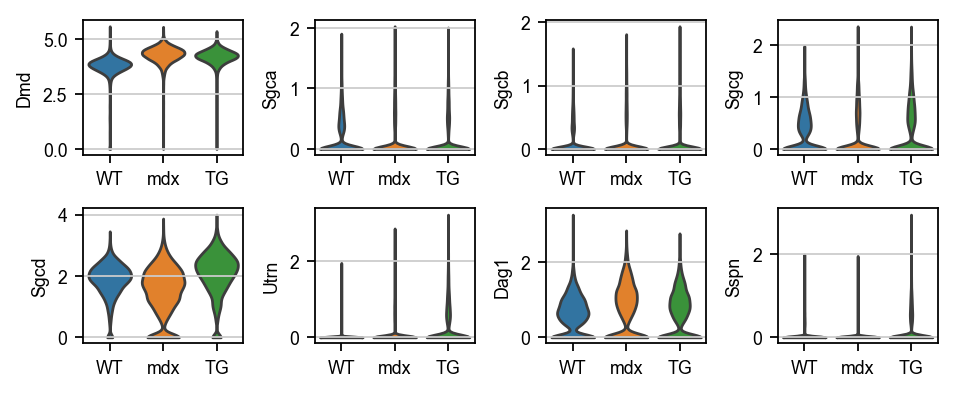

In [101]:
DGC_list = ["Dmd", "Sgca", "Sgcb", "Sgcg", "Sgcd", "Utrn", "Dag1", "Sspn"]

sc.set_figure_params(fontsize=8)

fig, axs = plt.subplots(2, 4, figsize=(6, 2.5))

for gene in DGC_list:

    sc.pl.violin(
        myonuclei,
        keys=gene,
        groupby="sample_id",
        ax=axs.flatten()[DGC_list.index(gene)],
        show=False,
        # jitter=0.3,
        stripplot=False,
        xlabel=None,
        size=0
    )

plt.tight_layout()

plt.savefig(
    "Figures/myonuclei_DGC_violin_plots.svg",
    dpi=600, 
    format='svg', 
    bbox_inches='tight', 
    transparent=True
    )

plt.show()

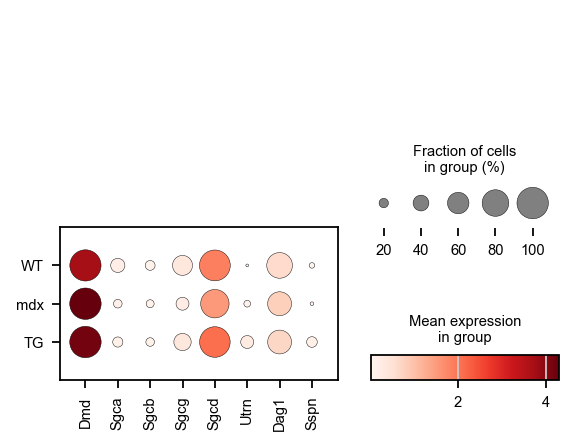

In [79]:
fig, axs = plt.subplots(figsize=(4, 3))

sc.pl.dotplot(
    myonuclei, 
    var_names=DGC_list, 
    groupby="sample_id", 
    show=True,
    # standard_scale="var",
    ax=axs
    )

In [16]:
plt.rcParams['font.size'] = 8
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['svg.fonttype'] = 'none'

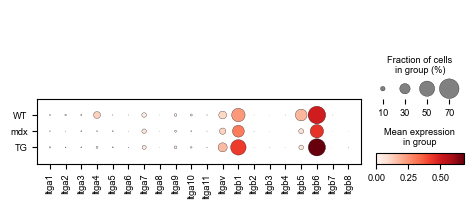

In [21]:
integrins = ['Itga1', 'Itga2', 'Itga3', 'Itga4', 'Itga5', 'Itga6', 'Itga7', 'Itga8', 'Itga9', 'Itga10', 'Itga11',
             'Itgav', 
             'Itgb1', 'Itgb2', 'Itgb3', 'Itgb4', 'Itgb5', 'Itgb6', 'Itgb7', 'Itgb8']

fig, axs = plt.subplots(figsize=(5.5, 2))

sc.pl.dotplot(
    myonuclei, 
    var_names=integrins, 
    groupby="sample_id", 
    show=False,
    # standard_scale="var",
    # categories_order=["WT", "mdx", "TG"],
    ax=axs
    )

plt.savefig("Figures/myonuclei_integrin_dotplot.svg",
            dpi=600,
            format='svg',
            bbox_inches='tight',
            transparent=True)

plt.show()

<h3> pseudobulk all myonclei for plotting </h3>

In [53]:
import decoupler as dc

In [54]:
# pseudobulk by summing counts for each genotype
myonuclei.obs_names_make_unique()
sum_data = dc.pp.pseudobulk(
    adata=myonuclei,
    sample_col="sample_id",
    groups_col=None,
    mode="sum",
    layer="counts" 
)

In [55]:
sc.pp.normalize_total(sum_data, target_sum=1e6)
sc.pp.log1p(sum_data)

In [56]:
new_order = ['WT', 'mdx', 'TG']
sum_data.obs['sample_id'] = sum_data.obs['sample_id'].cat.reorder_categories(new_order, ordered=True)

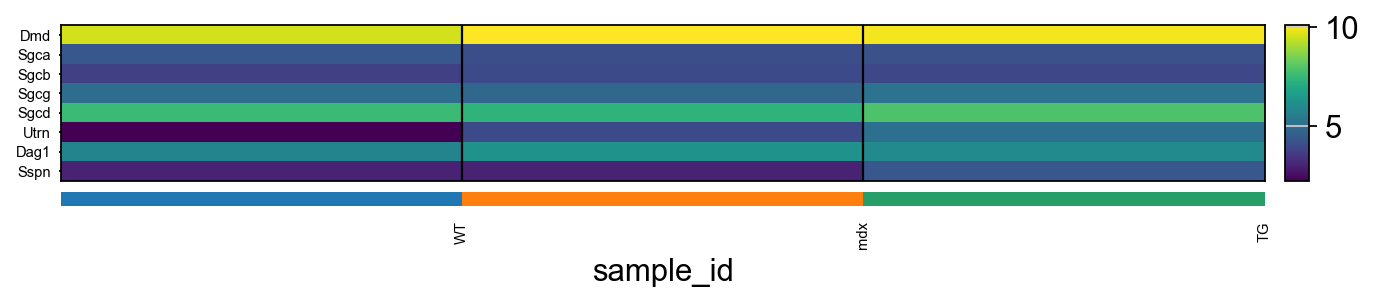

In [62]:
sc.pl.heatmap(
    sum_data, 
    var_names=DGC_list, 
    groupby="sample_id", 
    show=True,
    # standard_scale="var",
    swap_axes=True
    )

---
<h1> YAP genes all nuclei </h1>

In [2]:
all_data = ad.read_h5ad("processed_annotated.h5ad")

e:\mdx single cell and nuclei\.venv\Lib\site-packages\anndata\_core\anndata.py:1823: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [5]:
print(all_data.obs.cell_type.unique())

['Type 2b', 'Type 2a/x', 'MTJ', 'ECs', 'FAPs', ..., 'NMJ', 'Tenocyotes', 'Adipocytes', 'Schwann cells', 'Regenerating myonuclei']
Length: 13
Categories (13, object): ['Adipocytes', 'ECs', 'FAPs', 'Immune cells', ..., 'Smooth muscle', 'Tenocyotes', 'Type 2a/x', 'Type 2b']


In [6]:
myonuclei = all_data[all_data.obs["cell_type"].isin(["Type 2b", "Type 2a/x", "MTJ", "NMJ", "Regenerating myonuclei"])].copy()

e:\mdx single cell and nuclei\.venv\Lib\site-packages\anndata\_core\anndata.py:1823: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [8]:
import pandas as pd

In [10]:
YAP_targets = pd.read_excel("YAP target genes.xlsx", sheet_name=1)

In [11]:
cell_types = ["Type 2b", "Type 2a/x", "MTJ", "NMJ", "Regenerating myonuclei"]

In [13]:
sc.tl.score_genes(myonuclei, gene_list=YAP_targets["lower"].tolist(), score_name="YAP_score")

In [18]:
from sklearn.preprocessing import MinMaxScaler

# Extract scores
scores = myonuclei.obs['YAP_score'].values.reshape(-1, 1)

# Scale to 0-1
scaler = MinMaxScaler()
myonuclei.obs['YAP_score_scaled'] = scaler.fit_transform(scores)

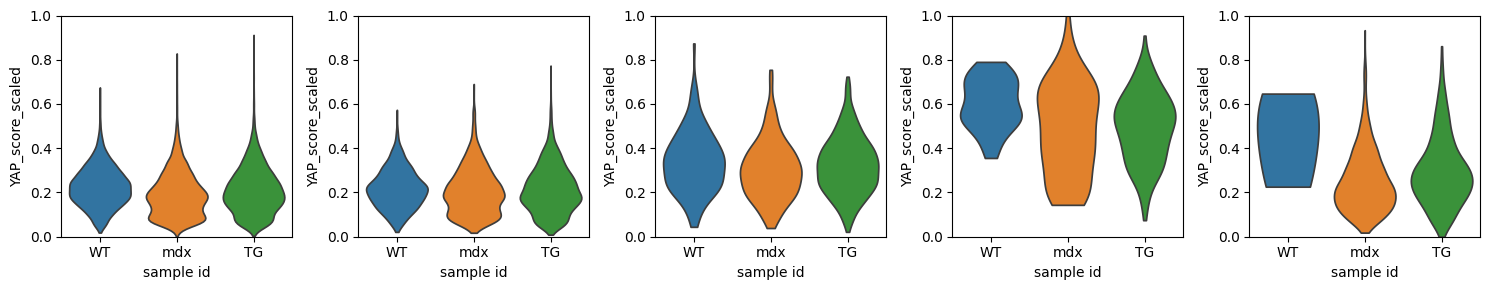

In [20]:
fig, axes = plt.subplots(1, len(cell_types), figsize=(15, 3))

for cell in cell_types:
    vlnplt = sc.pl.violin(
        myonuclei[myonuclei.obs["cell_type"] == cell], 
        keys="YAP_score_scaled", 
        groupby="sample_id", 
        jitter=0.3, 
        stripplot=True,
        show=False,
        size=0,
        
        ax=axes[cell_types.index(cell)]
    )

for ax in axes:
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()